<a href="https://colab.research.google.com/github/rmadatt/ADLAB/blob/main/RIVER_CONSERVATION_%2B_RARE_EVENTS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== SETUP DONE ===


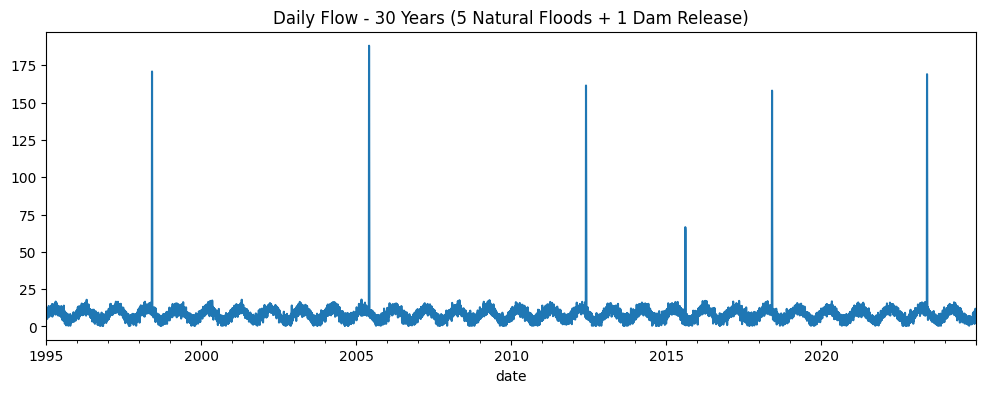


=== DESIGN FLOODS (GEV) ===
2-year flood: 16.7 m3/s
10-year flood: 73.0 m3/s
50-year flood: 1754.5 m3/s
100-year flood: 7366.9 m3/s
200-year flood: 30930.3 m3/s


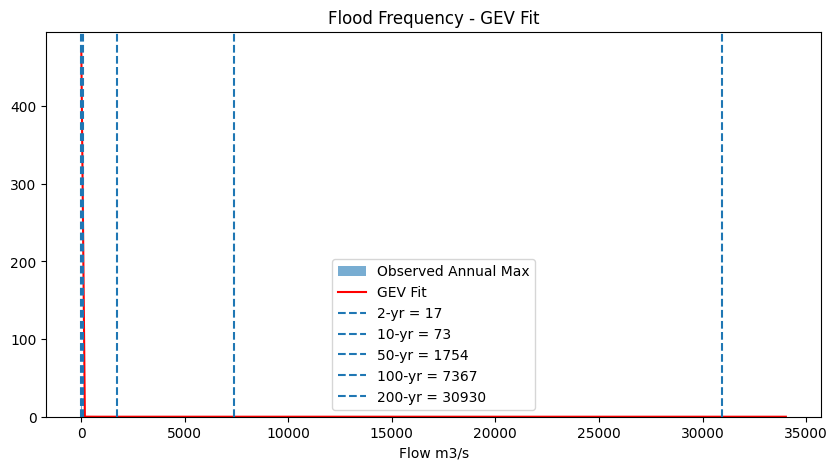


=== ANOMALIES ===
Found 33 anomaly days
classification
MAN-MADE? High flow, no rain - check dam log     25
NATURAL? High flow + rain - likely real flood     8
Name: count, dtype: int64


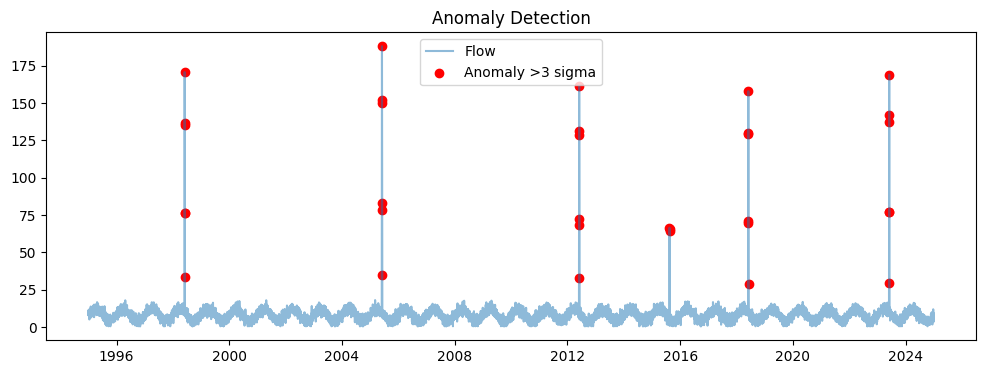

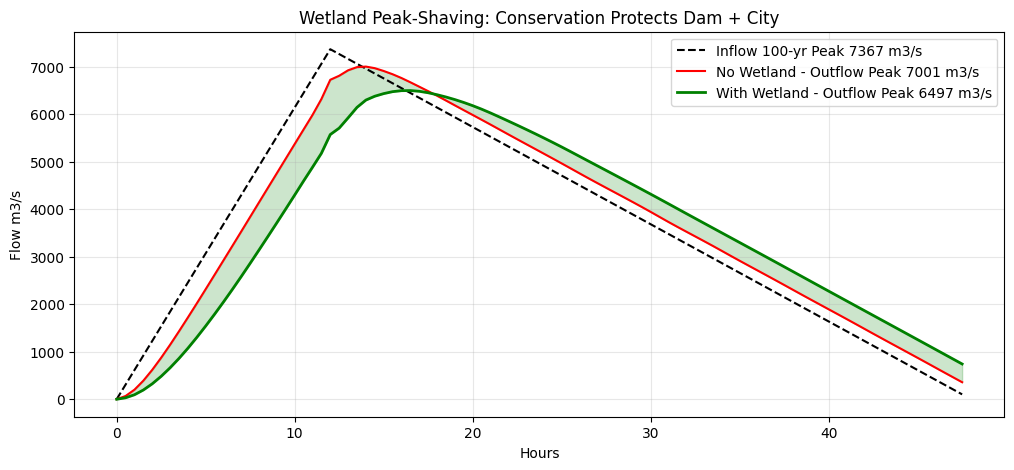


Wetland peak reduction: 7.2%
Inflow 7366.9 -> No wetland 7001.4 -> With wetland 6496.7

=== PREDICTIVE MODEL ===
R2 on test: 0.580
Feature importance: {'prev_flow': np.float64(0.793), 'rain_mm': np.float64(0.111), 'rain_3d': np.float64(0.096)}
Tomorrow predicted flow: 4.8 m3/s

=== WHAT TO DO WITH ANOMALIES ===
             Anomaly Type           Origin                                   Action                       Effect if Deleted
Natural Flood (e.g. 2023)          Natural     KEEP - Model with GEV, do not delete Underestimates 100-yr flood - dangerous
       Dam Release (2015)         Man-made           KEEP - Add dummy dam_release=1 Model thinks floods happen without rain
      Sensor Error (9999) Man-made (error)              REMOVE - Impute, log reason                   None - improves model
          Pollution Spike         Man-made KEEP - Investigate, flag for enforcement                 Misses pollution source

DONE - All plots + predictions complete


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [1]:
# RIVER CONSERVATION + RARE EVENTS - FULL NOTEBOOK IN ONE CELL
# Topics: Flood Frequency (GEV) + Dam Routing + Wetland Peak-Shaving + Anomaly Detection + Predictive Model
# Replace FAKE DATA section with your real CSV when ready

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.integrate import solve_ivp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
np.random.seed(42)
print("=== SETUP DONE ===")

# --- 1. FAKE DATA (REPLACE THIS) ---
# Real data: df = pd.read_csv('your_river.csv', parse_dates=['date'])
dates = pd.date_range('1995-01-01', '2024-12-31', freq='D')
base = 8 + 4*np.sin(2*np.pi*np.arange(len(dates))/365.25)
noise = np.random.normal(0, 2, len(dates))
flow = np.maximum(base + noise, 0.5)
for yr in [1998, 2005, 2012, 2018, 2023]:
    idx = np.where(dates.year == yr)[0][150]
    peak = np.random.uniform(120, 180)
    for i in range(7):
        flow[idx+i] += peak * np.exp(-0.5*((i-2)/1.5)**2)
idx_dam = np.where((dates.year == 2015) & (dates.month == 8) & (dates.day == 15))[0][0]
flow[idx_dam:idx_dam+3] += 60
df = pd.DataFrame({'date': dates, 'flow_m3s': flow, 'rain_mm': np.random.exponential(2, len(dates))})
df.set_index('date', inplace=True)
df['flow_m3s'].plot(figsize=(12,4), title='Daily Flow - 30 Years (5 Natural Floods + 1 Dam Release)')
plt.show()

# --- 2. FLOOD FREQUENCY - GEV ---
annual_max = df['flow_m3s'].resample('YE').max()
params = genextreme.fit(annual_max)
print("\n=== DESIGN FLOODS (GEV) ===")
design = {}
for T in [2, 10, 50, 100, 200]:
    q = genextreme.ppf(1 - 1/T, *params)
    design[T] = q
    print(f"{T}-year flood: {q:.1f} m3/s")
plt.figure(figsize=(10,5))
plt.hist(annual_max, bins=12, alpha=0.6, label='Observed Annual Max')
xs = np.linspace(annual_max.min(), design[200]*1.1, 200)
plt.plot(xs, len(annual_max)*genextreme.pdf(xs, *params)*(annual_max.max()-annual_max.min())/12, 'r-', label='GEV Fit')
for T, q in design.items():
    plt.axvline(q, linestyle='--', label=f'{T}-yr = {q:.0f}')
plt.legend(); plt.title('Flood Frequency - GEV Fit'); plt.xlabel('Flow m3/s'); plt.show()

# --- 3. ANOMALY DETECTION - NATURAL vs MAN-MADE ---
df['flow_z'] = (df['flow_m3s'] - df['flow_m3s'].mean()) / df['flow_m3s'].std()
df['anomaly'] = df['flow_z'] > 3
anomalies = df[df['anomaly']].copy()
def classify(row):
    if row['rain_mm'] < 5 and row['flow_m3s'] > 50:
        return 'MAN-MADE? High flow, no rain - check dam log'
    else:
        return 'NATURAL? High flow + rain - likely real flood'
anomalies['classification'] = anomalies.apply(classify, axis=1)
print("\n=== ANOMALIES ===")
print(f"Found {len(anomalies)} anomaly days")
print(anomalies['classification'].value_counts())
plt.figure(figsize=(12,4))
plt.plot(df.index, df['flow_m3s'], alpha=0.5, label='Flow')
plt.scatter(anomalies.index, anomalies['flow_m3s'], color='red', label='Anomaly >3 sigma')
plt.legend(); plt.title('Anomaly Detection'); plt.show()

# --- 4. DAM ROUTING + WETLAND PEAK-SHAVING (100-year flood) ---
def make_hydrograph(peak, duration=48):
    t = np.arange(0, duration, 0.5)
    q = np.where(t <= 12, peak * t/12, peak * (1 - (t-12)/36))
    return t, np.maximum(q, 0)
t, inflow = make_hydrograph(design[100])
def route(inflow, t, storage_factor=1.0, spillway_coeff=0.8):
    def model(t_, S):
        I = np.interp(t_, t, inflow)
        O = spillway_coeff * max(S[0], 0) / storage_factor
        return [I - O]
    sol = solve_ivp(model, [t[0], t[-1]], [0], t_eval=t, method='RK45')
    dS = np.gradient(sol.y[0], t)
    outflow = np.maximum(inflow - dS, 0)
    return sol.y[0], outflow
S_a, O_a = route(inflow, t, storage_factor=1.0)
S_b, O_b = route(inflow, t, storage_factor=2.5)
plt.figure(figsize=(12,5))
plt.plot(t, inflow, 'k--', label=f'Inflow 100-yr Peak {inflow.max():.0f} m3/s')
plt.plot(t, O_a, 'r-', label=f'No Wetland - Outflow Peak {O_a.max():.0f} m3/s')
plt.plot(t, O_b, 'g-', linewidth=2, label=f'With Wetland - Outflow Peak {O_b.max():.0f} m3/s')
plt.fill_between(t, O_b, O_a, alpha=0.2, color='green')
plt.legend(); plt.title('Wetland Peak-Shaving: Conservation Protects Dam + City'); plt.xlabel('Hours'); plt.ylabel('Flow m3/s'); plt.grid(alpha=0.3); plt.show()
reduction = (O_a.max() - O_b.max()) / O_a.max() * 100
print(f"\nWetland peak reduction: {reduction:.1f}%")
print(f"Inflow {inflow.max():.1f} -> No wetland {O_a.max():.1f} -> With wetland {O_b.max():.1f}")

# --- 5. PREDICTIVE MODEL - FLOW FORECAST ---
df_model = df.copy()
df_model['prev_flow'] = df_model['flow_m3s'].shift(1)
df_model['rain_3d'] = df_model['rain_mm'].rolling(3).sum()
df_model = df_model.dropna()
X = df_model[['prev_flow', 'rain_mm', 'rain_3d']]
y = df_model['flow_m3s']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)
print(f"\n=== PREDICTIVE MODEL ===")
print(f"R2 on test: {model.score(X_test, y_test):.3f}")
print(f"Feature importance: {dict(zip(X.columns, model.feature_importances_.round(3)))}")
print(f"Tomorrow predicted flow: {model.predict(df_model.iloc[-1][['prev_flow','rain_mm','rain_3d']].values.reshape(1,-1))[0]:.1f} m3/s")

# --- 6. ANOMALY ACTION TABLE ---
summary = pd.DataFrame({
    'Anomaly Type': ['Natural Flood (e.g. 2023)', 'Dam Release (2015)', 'Sensor Error (9999)', 'Pollution Spike'],
    'Origin': ['Natural', 'Man-made', 'Man-made (error)', 'Man-made'],
    'Action': ['KEEP - Model with GEV, do not delete', 'KEEP - Add dummy dam_release=1', 'REMOVE - Impute, log reason', 'KEEP - Investigate, flag for enforcement'],
    'Effect if Deleted': ['Underestimates 100-yr flood - dangerous', 'Model thinks floods happen without rain', 'None - improves model', 'Misses pollution source']
})
print("\n=== WHAT TO DO WITH ANOMALIES ===")
print(summary.to_string(index=False))
print("\nDONE - All plots + predictions complete")